<h1 style="
    font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
    font-size: 36px;
    color: #ffffff;
    background-color: #9E1B32;
    padding: 20px;
    border-radius: 12px;
    text-align: center;
    box-shadow: 0px 4px 10px rgba(0, 0, 0, 0.1);">
    NextGen Data Preparation
</h1>

**Authors:** 

<ul style="line-height:1.5;">
<li>Savalan Naser Neisary <a href="mailto:snaserneisary@crimson.ua.edu">(snaserneisary@crimson.ua.edu)</a></li>
</ul>

**Last Updated:** 10/10/2026

**Purpose:**

This notebook presents how to get the input data for a NextGen run by subsetting the hydrofabric, downloading forcing data, and creating the model configuration and realization files. More details on NextGen data preparation are available at this [**link**](https://pypi.org/project/ngiab-data-preprocess/).

**Audience:**

Researchers and practitioners with some experience in Jupyter Notebooks, basic Python, and basic hydrologic data analysis.

**Description:**

The user defines a location with a gage ID, catchment ID, or Vector Processing Unit (VPU), and sets the start and end dates of the period of interest. Geometry and model attributes come from the [**Hydrofabric Dataset**](https://communityhydrofabric.s3.us-east-1.amazonaws.com/index.html#hydrofabrics/community/). Forcings are based on AORC data at 1-km grid resolution and are calculated as a weighted mean of the gridded AORC values, with the weights obtained from the `Exact Extract` tool and computed using `NumPy`.

**Data Description:**

This notebook automatically builds a complete run package for NextGen simulations. It extracts geometry and model attributes from [**Hydrofabric Dataset**](https://communityhydrofabric.s3.us-east-1.amazonaws.com/index.html#hydrofabrics/community/), with detailed documentation available [**here**](https://lynker-spatial.s3-us-west-2.amazonaws.com/hydrofabric/v2.2/hfv2.2-data_model.html). It uses AORC meteorological forcing data at 1-km grid resolution and creates every configuration file needed for the simulation: the NextGen model configuration (`realization.json`), the routing configuration (`troute.yaml`), and the model parameter files of each divide (subcatchment).

It also relies on code in `hydrofabric_visualization_utils.py` and `forcings_visualization_utilis.py`.

<div style="padding: 15px 20px; background-color: rgba(184,34,61,0.12); border-left: 6px solid #9E1B32; border-radius: 4px; margin-bottom: 10px;">
<h3 style="margin-top: 0; font-weight: 700;">❗ We created this tutorial based on the tutorial in the <a href="https://www.hydroshare.org/resource/27045581bdea4808a393330f2417379c/" target="_blank"><strong>NextGen Water Modeling Workflow for Research-Scale Applications Hydroshare resources</strong></a>.</h3>

Nassar, A., Tarboton, D., Baig, F., Patel, A., Cunningham, J., Salehabadi, H. (2026). NextGen Water Modeling Workflow for Research-Scale Applications, HydroShare, https://doi.org/10.4211/hs.27045581bdea4808a393330f2417379c, DOI for this published resource is pending activation.
</div>

<div style="
    padding: 15px 20px; 
    background-color: rgba(184,34,61,0.12); 
    border-left: 6px solid #9E1B32; 
    border-radius: 4px; 
    margin-bottom: 20px;
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
">
    <h3 style="margin-top: 0; font-weight: 700; display: flex; align-items: center; gap: 8px;">
        💡 Quick Note Before You Begin
    </h3>
    <p style="margin-bottom: 10px; font-size: 1.05em;">
        So that everything runs smoothly and all settings start correctly, <strong>please restart the kernel before running the cells below</strong> by opening the <strong>Kernel</strong> menu at the top and choosing <span style="background-color: rgba(0,0,0,0.05); padding: 2px 6px; border-radius: 3px; border: 1px solid rgba(0,0,0,0.1);"><strong>“Restart Kernel and Clear Outputs of All Cells”</strong></span>.
    </p>

</div>

<div style="background:#9E1B32; border-left:6px solid #F0627A; padding:12px 16px; border-radius:8px; margin-top:0px; margin-bottom:0px;">
  <h3 style="margin:0; font-size:20px; font-weight:700; color:#fff5f7;">
    1. Prepare the Python Environment
  </h3>
</div>

This section imports all the **Python libraries and modules** needed in this workflow.  
Two specialized visualization modules, built for working with **NextGen HydroFabric** and **Forcing datasets**, are used in this notebook.

<div style="background-color:rgba(184,34,61,0.12); border-left: 5px solid #E04A63; padding: 14px; border-radius: 8px; font-family: 'Segoe UI', sans-serif; font-size: 15px; margin-top: 10px;">
  <strong>Key Modules Used:</strong>
  <ul style="margin-top: 8px; margin-bottom: 0;">
    <li><strong><code>hydrofabric_visualization_utils</code></strong> — Offers tools to visualize HydroFabric datasets.
    <li><strong><code>forcings_utils</code></strong> — Offers functions that aggregate AORC forcing variables 
      (e.g., precipitation, temperature, wind) from the **divide scale** to the **watershed scale**, 
      which supports spatiotemporal analysis and visualization.</li>
  </ul>
</div>

In [1]:
# ----------------------------- Importing Required Libraries -----------------------------

import json
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from utils.hydrofabric_visualization_utils import conus_hydrofabric_download, display_hydrofabric_map
from utils.workshop_paths import DATA_DIR, FIGURES_DIR, set_preprocess_output_dir
from utils.forcings_utils import (
    process_time_series,
    get_var_label,
    get_var_full_name,
    get_var_units,
    list_supported_variables,
    compute_mean_annual,   # main function that calculates the annual mean values
    join_to_gpkg,          # merges result statistics to polygon divides GPKG
    save_csv_and_gpkg,     # writes CSV + merged GPKG output files
    plot_mean_annual_map,  # makes the map visualization
    make_mean_annual_map  
)
from utils.data_prep_plots import (
    plot_hourly_series,
    plot_streamflow_series,
    plot_cumulative_series,
    plot_mean_annual_basin_map,
    plot_raw_gridded_map,
)

<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)


<div style="background:#9E1B32; border-left:6px solid #F0627A; padding:12px 16px; border-radius:8px; margin-top:0; margin-bottom:0;">
  <h3 style="margin:0; font-size:20px; font-weight:700; color:#fff5f7;">
    2. Set Inputs
  </h3>
</div>

<p style="margin-top:0; padding-top:4px;">
Here you set the <strong>key input variables</strong> needed for <strong>NextGen data preprocessing</strong>.  
They determine the <strong>spatial domain of interest</strong> and the <strong>temporal range</strong> used when extracting and processing the data.
</p>

<div style="background-color:rgba(184,34,61,0.12); border-left: 5px solid #E04A63; padding: 14px; border-radius: 8px; font-family: 'Segoe UI', sans-serif; font-size: 15px; margin-top: 10px;">
  <strong>Inputs Defined in the Next Cell:</strong>
  <ul style="margin-top: 8px; margin-bottom: 0;">
    <li><strong>Hydrofabric ID:</strong> Sets the spatial domain of interest. It can be:
      <ul>
        <li>A <em>catchment ID</em> (e.g., <code>cat-7080</code>)</li>
        <li>A <em>gage ID</em> (e.g., <code>gage-02450250</code>)</li>
        <li>A <em>Vector Processing Unit (VPU)</em> code (e.g., <code>01</code>)</li>
      </ul>
    </li>
    <li><strong>Start Date:</strong> The first day of the simulation or data extraction period (format: <code>YYYY-MM-DD</code>).</li>
    <li><strong>End Date:</strong> The last day of the simulation or data extraction period (format: <code>YYYY-MM-DD</code>).</li>
  </ul>
</div>


In [2]:
# Save all NGIAB data in the 'ngiab_preprocess_output' folder next to these notebooks
set_preprocess_output_dir()

# Define your Hydrofabric ID
hydrofabric_id = "gage-02450250"  # This can be a catchment ID, a gage ID, or a Vector Processing Unit (VPU) code.

# Start date
start_date = "2017-10-01"    # Specify the start date in the format 'YYYY-MM-DD'

# End date
end_date = "2017-11-30"      # Specify the end date in the format 'YYYY-MM-DD'

# If we want it to run all the cells using the internet. Setting it to 'yes' will take longer. 
online = 'yes'

NGIAB outputs folder: /home/jovyan/workshop/ngiab_preprocess_output


<div style="background:#9E1B32; border-left:6px solid #F0627A; padding:12px 16px; border-radius:8px; margin-top:0; margin-bottom:0;">
  <h3 style="margin:0; font-size:20px; font-weight:700; color:#fff5f7;">
    3. Subset Hydrofabric using Catchment ID, Gage ID, or VPU
  </h3>
</div>

<p style="margin-top:0; padding-top:4px;">
This section outlines the whole upstream area of your point of interest (e.g., a catchment, gage or flowpath) and saves it as a GeoPackage. You can find more about the hydrofabric IDs that can define the spatial domain of interest in this 
<a href="https://pypi.org/project/ngiab-data-preprocess/"><strong>link</strong></a>. 
Geometry and model attributes are taken from the 
<a href="https://communityhydrofabric.s3.us-east-1.amazonaws.com/index.html#hydrofabrics/community/"><strong>Hydrofabric Dataset</strong></a>, 
and more details on all the data sources are available 
<a href="https://lynker-spatial.s3-us-west-2.amazonaws.com/hydrofabric/v2.2/hfv2.2-data_model.html"><strong>here</strong></a>.
</p>


<div style="background-color:rgba(184,34,61,0.12); border-left: 5px solid #E04A63; padding: 12px; border-radius: 6px; font-family: 'Fira Code', monospace; font-size: 14px; margin-top: 12px;">
  <strong>Command:</strong>
  <pre style="margin-top: 10px; background-color:#1e1e1e; color:#ffffff; padding:10px; border-radius:6px;"><code>!source /ngen/.venv/bin/activate && python -m ngiab_data_cli -i $hydrofabric_id -s</code></pre>
</div>

#### Command Breakdown

<table style="border-collapse: collapse; width: 100%; font-size: 14px;">
  <thead>
    <tr style="background-color: #ffffff; color: #9E1B32;">
      <th style="padding: 8px; text-align: left; color: #9E1B32; border-bottom: 2px solid #9E1B32;">Argument</th>
      <th style="padding: 8px; text-align: left; color: #9E1B32; border-bottom: 2px solid #9E1B32;">Description</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding: 8px; text-align: left;"><code>!source /ngen/.venv/bin/activate</code></td>
      <td style="padding: 8px; text-align: left;">Turns on the Python virtual environment that contains all the <code>NextGen</code> and <code>ngiab_data_cli</code> dependencies.</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code>python -m ngiab_data_cli</code></td>
      <td style="padding: 8px; text-align: left;">Runs the <code>ngiab_data_cli</code> module, which takes care of data preprocessing and forcing generation for the HydroFabric subset.</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code>-i "$hydrofabric_id"</code></td>
      <td style="padding: 8px; text-align: left;">Gives the unique HydroFabric subset ID (e.g., a gage or catchment identifier) to generate data for.</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code>-f</code></td>
      <td style="padding: 8px; text-align: left;">Overwrites any output files that already exist in the subset directory.</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code>--start "$start_date"</code></td>
      <td style="padding: 8px; text-align: left;">Sets the first date of the forcing dataset (e.g., <code>2020-01-01</code>).</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code>--end "$end_date"</code></td>
      <td style="padding: 8px; text-align: left;">Sets the last date of the forcing dataset (e.g., <code>2020-12-31</code>).</td>
    </tr>
  </tbody>
</table>

<div style="background-color:rgba(184,34,61,0.12); border-left: 5px solid #E04A63; padding: 12px; border-radius: 6px; font-family: 'Segoe UI', sans-serif; font-size: 14px; margin-top: 12px;">
  💡 <strong>Tip:</strong> Additional arguments and usage options for the <code>ngiab_data_cli</code> hydrofabric subset command are described in the official documentation:<br>
  <a href="https://pypi.org/project/ngiab-data-preprocess/" target="_blank">https://pypi.org/project/ngiab-data-preprocess/</a>
</div>

In [3]:
### CONUS HydroFabric download
# Downloads the national (CONUS) hydrofabric dataset if it is not already on this machine (`~/.ngiab`).  
# **First run only** — may take **2–3 minutes**; later runs skip download if data is present.

if online == 'yes':
    conus_hydrofabric_download()

In [4]:
%%time
# Subsetting the HydroFabric Dataset
# This step subsets the HydroFabric dataset using the `hydrofabric_id` variable defined in the previous cell.

if online == 'yes':
    !source /ngen/.venv/bin/activate && python -m ngiab_data_cli -i $hydrofabric_id -s

⠴ loading<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)
⠏ loading
2026-11-06 22:54:50,031 - INFO - Getting catid for 02450250, in /home/jovyan/.ngiab/hydrofabric/v2.2/conus_nextgen.gpkg
2026-11-06 22:54:50,045 - INFO - Found cat-486182 from gage-02450250
2026-11-06 22:54:50,047 - INFO - Processing cat-486182 in /home/jovyan/workshop/ngiab_preprocess_output/gage-02450250
2026-11-06 22:54:53,957 - INFO - Upstream catchments: 31
2026-11-06 22:54:53,958 - INFO - Subsetting hydrofabric
2026-11-06 22:54:54,851 - INFO - Subsetting tables: ['divides', 'divide-attributes', 'flowpath-attributes', 'flowpath-attributes-ml', 'flowpaths', 'hydrolocations', 'nexus', 'pois', 'lakes', 'network']
2026-11-06 22:55:00,992 - INFO - Subset complete for 75 features (catchments + nexuses)
2026-11-06 22:55:00,993 - INFO - Subsetting complete.
2026-11-06 22:55:00,994 - INFO - All operations completed successfully.


<div style="border-left: 6px solid #9E1B32; background:rgba(184,34,61,0.10); padding:12px 14px; border-radius:8px;">
  💡 <strong>Tip:</strong> In this notebook example, the Hydrofabric subset is stored at:<br>
  <code>ngiab_preprocess_output/ (in the notebooks folder)/{hydrofabric_id}/config</code><br><br>
  For example:<br>
  <code>ngiab_preprocess_output/ (in the notebooks folder)/gage-02450250/config</code>
</div>

Display the hydrofabric subset on an interactive map that shows its main features: divides (polygons), flowpaths (lines), nexus (points) and gages (pin markers).

### 🗺️ Visualizing the HydroFabric Subset

In this step, you **view the HydroFabric subset** on an interactive map to inspect the main hydrologic features obtained when the subset was created.  
The map gives spatial context and lets you check that the subset is correct.

<div style="background-color:rgba(184,34,61,0.12); border-left: 5px solid #E04A63; padding: 14px; border-radius: 8px; font-family: 'Segoe UI', sans-serif; font-size: 15px; margin-top: 12px;">
  <strong>Goal:</strong> Show the main HydroFabric components on an interactive map:
  <ul style="margin-top: 8px; margin-bottom: 0;">
    <li><strong>Divides:</strong> Polygon boundaries (black outlines) that represent watershed or catchment areas.</li>
    <li><strong>Flowpaths:</strong> Blue lines that represent flow directions or stream reaches.</li>
    <li><strong>Nexus:</strong> Red circular markers for hydrologic connection nodes.</li>
    <li><strong>Gages:</strong> Points (shown as pin markers) for monitoring stations.</li>
  </ul>
</div>

In [5]:
# Provide the path to your GeoPackage
gpkg_path = f"{DATA_DIR}/{hydrofabric_id}/config/{hydrofabric_id}_subset.gpkg"

# Display the interactive map
display_hydrofabric_map(gpkg_path)

<div style="background:#9E1B32; border-left:6px solid #F0627A; padding:12px 16px; border-radius:8px; margin-top:0; margin-bottom:0;">
  <h3 style="margin:0; font-size:20px; font-weight:700; color:#fff5f7;">
    4. Generate Forcings for a Specific Catchment ID
  </h3>
</div>

<p style="margin-top:0; margin-bottom:0; padding-top:4px;">
This step subsets and downloads the forcing data and then aggregates it for every divide (subcatchment) in the spatial domain. It uses the start and end dates defined earlier for the period of interest.
</p>


<div style="background-color:rgba(184,34,61,0.12); border-left: 5px solid #E04A63; padding: 12px; border-radius: 6px; font-family: 'Fira Code', monospace; font-size: 14px; margin-top: 12px;">
  <strong>Command:
  <pre style="margin-top: 10px; background-color:#1e1e1e; color:#ffffff; padding:10px; border-radius:6px; overflow-x:auto;"><code>!source /ngen/.venv/bin/activate && python -m ngiab_data_cli -i "$hydrofabric_id" -f --start "$start_date" --end "$end_date"</code></pre>
</div>

#### Command Breakdown

<table style="border-collapse: collapse; width: 100%; font-size: 14px;">
  <thead>
    <tr style="background-color: #ffffff; color: #9E1B32;">
      <th style="padding: 8px; text-align: left; color: #9E1B32; border-bottom: 2px solid #9E1B32;">Argument</th>
      <th style="padding: 8px; text-align: left; color: #9E1B32; border-bottom: 2px solid #9E1B32;">Description</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding: 8px; text-align: left;"><code>!source /ngen/.venv/bin/activate</code></td>
      <td style="padding: 8px; text-align: left;">Turns on the Python virtual environment that contains all the <code>NextGen</code> and <code>ngiab_data_cli</code> dependencies.</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code>python -m ngiab_data_cli</code></td>
      <td style="padding: 8px; text-align: left;">Runs the <code>ngiab_data_cli</code> module, which takes care of data preprocessing and forcing generation for the HydroFabric subset.</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code>-i "$hydrofabric_id"</code></td>
      <td style="padding: 8px; text-align: left;">Gives the unique HydroFabric subset ID (e.g., a gage or catchment identifier) to generate data for.</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code>-f</code></td>
      <td style="padding: 8px; text-align: left;">Overwrites any output files that already exist in the subset directory.</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code>--start "$start_date"</code></td>
      <td style="padding: 8px; text-align: left;">Sets the first date of the forcing dataset (e.g., <code>2020-01-01</code>).</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code>--end "$end_date"</code></td>
      <td style="padding: 8px; text-align: left;">Sets the last date of the forcing dataset (e.g., <code>2020-12-31</code>).</td>
    </tr>
  </tbody>
</table>

<div style="background-color:rgba(184,34,61,0.12); border-left: 5px solid #E04A63; padding: 12px; border-radius: 6px; font-family: 'Segoe UI', sans-serif; font-size: 14px; margin-top: 12px;">
  💡 <strong>Tip:</strong> Additional arguments and usage options for the <code>ngiab_data_cli</code> forcing subset command are described in the official documentation:<br>
  <a href="https://pypi.org/project/ngiab-data-preprocess/" target="_blank">https://pypi.org/project/ngiab-data-preprocess/</a>
</div>

In [6]:
%%time
# Subsetting the Forcings Dataset
# Use the variables defined earlier (`hydrofabric_id`, `start_date`, `end_date`) to 
# subset and preprocess the AORC forcings for your HydroFabric subset.

if online == 'yes':
    !source /ngen/.venv/bin/activate && python -m ngiab_data_cli -i "$hydrofabric_id" -f --start "$start_date" --end "$end_date" --lstm_rust

⠼ loading<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)
⠦ loading
2026-11-06 22:59:07,750 - INFO - Getting catid for 02450250, in /home/jovyan/.ngiab/hydrofabric/v2.2/conus_nextgen.gpkg
2026-11-06 22:59:07,771 - INFO - Found cat-486182 from gage-02450250
2026-11-06 22:59:07,773 - INFO - Processing cat-486182 in /home/jovyan/workshop/ngiab_preprocess_output/gage-02450250
2026-11-06 22:59:11,690 - INFO - Upstream catchments: 31
2026-11-06 22:59:11,691 - INFO - Generating forcings from 2017-10-01 00:00:00 to 2017-11-30 00:00:00...
<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)
<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)
<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemallo

<h3 style="text-align: center; font-size: 20px; font-family: 'Segoe UI', sans-serif; margin-bottom: 10px; ">
  🌧️ <strong>AORC Forcing Inputs</strong>
</h3>

<table style="border-collapse: collapse; width: 100%; font-family: 'Segoe UI', sans-serif; font-size: 14px; border: 1px solid #d0d7de;">
  <thead>
    <tr style="background-color: #ffffff; color: #9E1B32;">
      <th style="padding: 10px; text-align: left; color: #9E1B32; border-bottom: 2px solid #9E1B32;">Variable Name</th>
      <th style="padding: 10px; text-align: left; color: #9E1B32; border-bottom: 2px solid #9E1B32;">Description</th>
      <th style="padding: 10px; text-align: left; color: #9E1B32; border-bottom: 2px solid #9E1B32;">Units</th>
    </tr>
  </thead>
  <tbody>
    <tr style="background-color: rgba(184,34,61,0.08);">
      <td style="padding: 8px; text-align: left;"><code><strong>APCP_surface</strong></code></td>
      <td style="padding: 8px; text-align: left;">Precipitation at the surface level</td>
      <td style="padding: 8px; text-align: left;">Meters (m)</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code><strong>DLWRF_surface</strong></code></td>
      <td style="padding: 8px; text-align: left;">Downward Longwave Radiation Flux at the surface</td>
      <td style="padding: 8px; text-align: left;">Watts per square meter (W/m²)</td>
    </tr>
    <tr style="background-color: rgba(184,34,61,0.08);">
      <td style="padding: 8px; text-align: left;"><code><strong>PRES_surface</strong></code></td>
      <td style="padding: 8px; text-align: left;">Air Pressure at the surface</td>
      <td style="padding: 8px; text-align: left;">Pascals (Pa)</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code><strong>SPFH_2maboveground</strong></code></td>
      <td style="padding: 8px; text-align: left;">Specific Humidity at 2 meters Above Ground Level</td>
      <td style="padding: 8px; text-align: left;">Kilograms per kilogram (kg/kg)</td>
    </tr>
    <tr style="background-color: rgba(184,34,61,0.08);">
      <td style="padding: 8px; text-align: left;"><code><strong>precip_rate</strong></code></td>
      <td style="padding: 8px; text-align: left;">Precipitation rate at the surface</td>
      <td style="padding: 8px; text-align: left;">Meters per second (m/s)</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code><strong>DSWRF_surface</strong></code></td>
      <td style="padding: 8px; text-align: left;">Downward Shortwave Radiation Flux at the surface</td>
      <td style="padding: 8px; text-align: left;">Watts per square meter (W/m²)</td>
    </tr>
    <tr style="background-color: rgba(184,34,61,0.08);">
      <td style="padding: 8px; text-align: left;"><code><strong>TMP_2maboveground</strong></code></td>
      <td style="padding: 8px; text-align: left;">Temperature at 2 meters Above Ground Level</td>
      <td style="padding: 8px; text-align: left;">Kelvin (K)</td>
    </tr>
    <tr>
      <td style="padding: 8px; text-align: left;"><code><strong>UGRD_10maboveground</strong></code></td>
      <td style="padding: 8px; text-align: left;">Eastward (U) Wind component at 10 meters Above Ground Level</td>
      <td style="padding: 8px; text-align: left;">Meters per second (m/s)</td>
    </tr>
    <tr style="background-color: rgba(184,34,61,0.08);">
      <td style="padding: 8px; text-align: left;"><code><strong>VGRD_10maboveground</strong></code></td>
      <td style="padding: 8px; text-align: left;">Northward (V) Wind component at 10 meters Above Ground Level</td>
      <td style="padding: 8px; text-align: left;">Meters per second (m/s)</td>
    </tr>
  </tbody>
</table>


<h3 style="background-color:#E04A63; color:white; padding:10px 14px; border-radius:6px; font-family:'Segoe UI',sans-serif; font-size:18px;">
📈 Visualizing Forcing Time-Series
</h3>

<p style="font-family:'Segoe UI',sans-serif; font-size:15px; margin-top:8px;">
Plot time series of different forcing variables to understand their <strong>trends</strong>, <strong>patterns</strong> and <strong>relationships</strong> over time.  
The plots show how key meteorological drivers such as precipitation, temperature, radiation and wind behave over time.
</p>


<h4 style="background-color:rgba(184,34,61,0.18); padding:8px 12px; border-left: 5px solid #E04A63; border-radius:6px; font-family:'Segoe UI',sans-serif; font-size:16px; margin-top:16px;">
🔹 Selecting the Forcing Variable and Input Paths
</h4>
<p style="font-family:'Segoe UI',sans-serif; font-size:15px; margin-top:6px;">
Choose the <strong>forcing variable</strong> to analyze (from the AORC table above),  
and set the file paths of the <strong>Forcings NetCDF dataset</strong> <code>forcings_path</code> and of the matching  
<strong>HydroFabric GeoPackage</strong> <code>gpkg_path</code> for your chosen <code>hydrofabric_id</code>.  
These inputs are used to extract and plot the time series of the variable.
</p>

In [7]:
# Specify the variable name from the table above
var_name = "precip_rate"  # Choose the variable to analyze

# Define the path of forcings
forcings_path = f"{DATA_DIR}/{hydrofabric_id}/forcings/forcings.nc"

# Define the path of hydrofabric geopackage dataset
gpkg_path = f"{DATA_DIR}/{hydrofabric_id}/config/{hydrofabric_id}_subset.gpkg"

<h4 style="background-color:rgba(184,34,61,0.18); padding:8px 12px; border-left: 5px solid #E04A63; border-radius:6px; font-family:'Segoe UI',sans-serif; font-size:16px; margin-top:16px;">
🔹 Hourly Time-Series Plot for the Selected Forcing Variable
</h4>

Saved plot to: /home/jovyan/workshop/figures/hourly_precip_rate.png


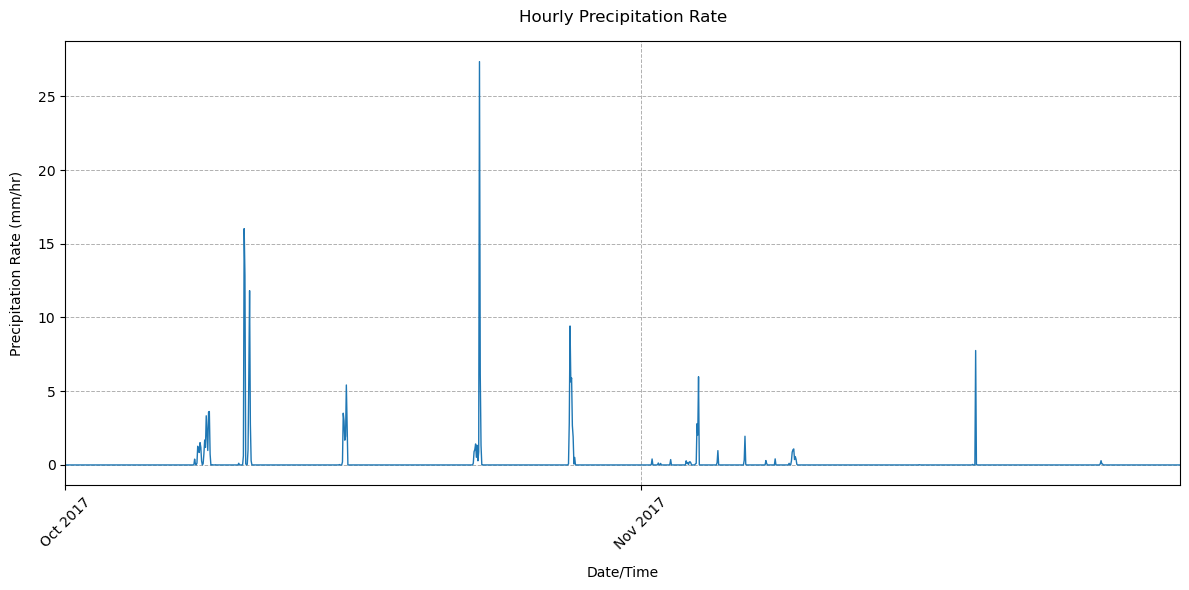

In [8]:
# Hourly time series of the selected variable
plot_hourly_series(forcings_path, gpkg_path, var_name)

<h4 style="background-color:rgba(184,34,61,0.18); padding:8px 12px; border-left: 5px solid #E04A63; border-radius:6px; font-family:'Segoe UI',sans-serif; font-size:16px; margin-top:16px;">
🔹 Daily Streamflow for the Same Period (Observed, NWM and NextGen)
</h4>

Saved plot to: /home/jovyan/workshop/figures/streamflow_2017-10-01_2017-11-30.png


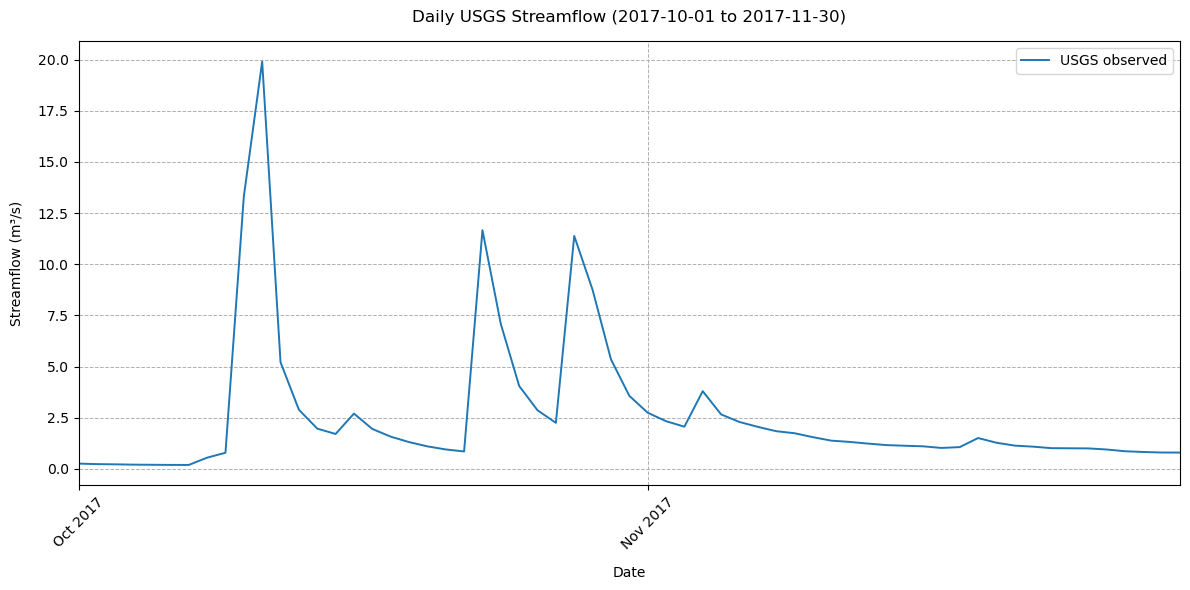

In [9]:
# Streamflow for the same period, from daily_flows.parquet
plot_streamflow_series(start_date, end_date)

<h4 style="background-color:rgba(184,34,61,0.18); padding:8px 12px; border-left: 5px solid #E04A63; border-radius:6px; font-family:'Segoe UI',sans-serif; font-size:16px; margin-top:16px;">
🔹 Cumulative Plot for the Selected Forcing Variable
</h4>

Saved cumulative plot to: /home/jovyan/workshop/figures/cumulative_precip_rate.png


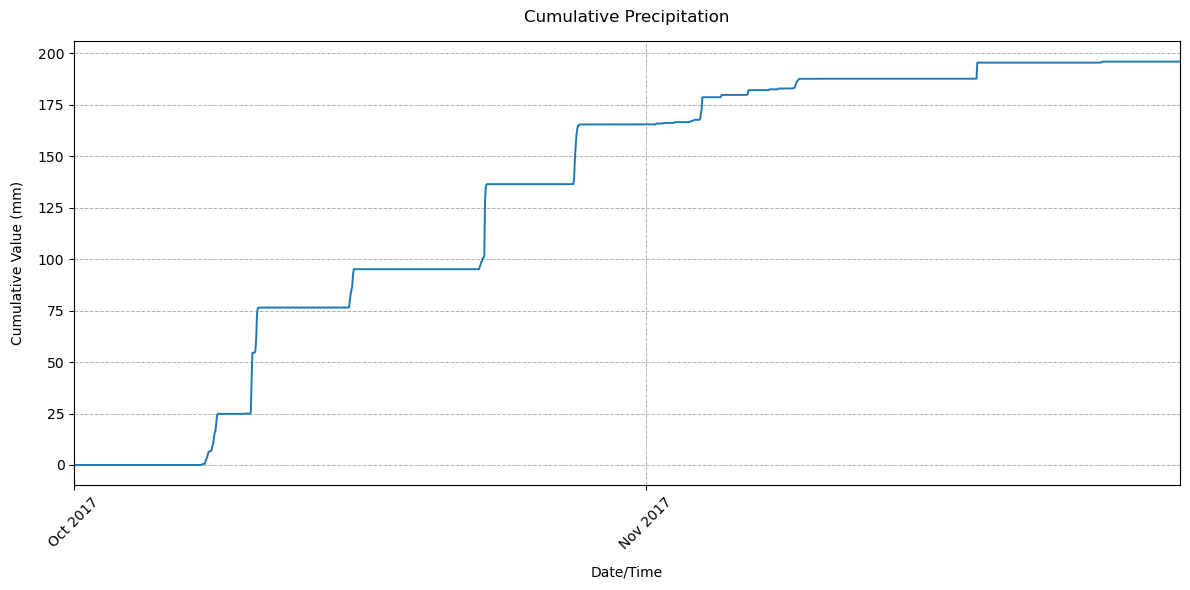

In [10]:
# Cumulative time series of the selected variable
plot_cumulative_series(forcings_path, gpkg_path, var_name)

<h4 style="background-color:rgba(184,34,61,0.18); padding:8px 12px; border-left: 5px solid #E04A63; border-radius:6px; font-family:'Segoe UI',sans-serif; font-size:16px; margin-top:16px;">
🔹 Compute Mean Annual Basin-Averaged Values and Generate Spatial Map Visualization
</h4>

<div style="background-color:rgba(184,34,61,0.12); border-left:4px solid #E04A63; padding:6px 10px; border-radius:6px; font-size:14px; margin-top:4px; margin-bottom:8px;">
<strong>Spatially Averaged Forcing Map</strong><br>
Forcing source path:<br>
<code>/home/jovyan/ngiab_preprocess_output/{hydrofabric_id}/forcings/forcings.nc</code>
</div>


Detected Kind: rate | Units: mm s^-1 | Rate base: per_second
Saved PNG map to: /home/jovyan/workshop/figures/mean_annual_precip_rate.png


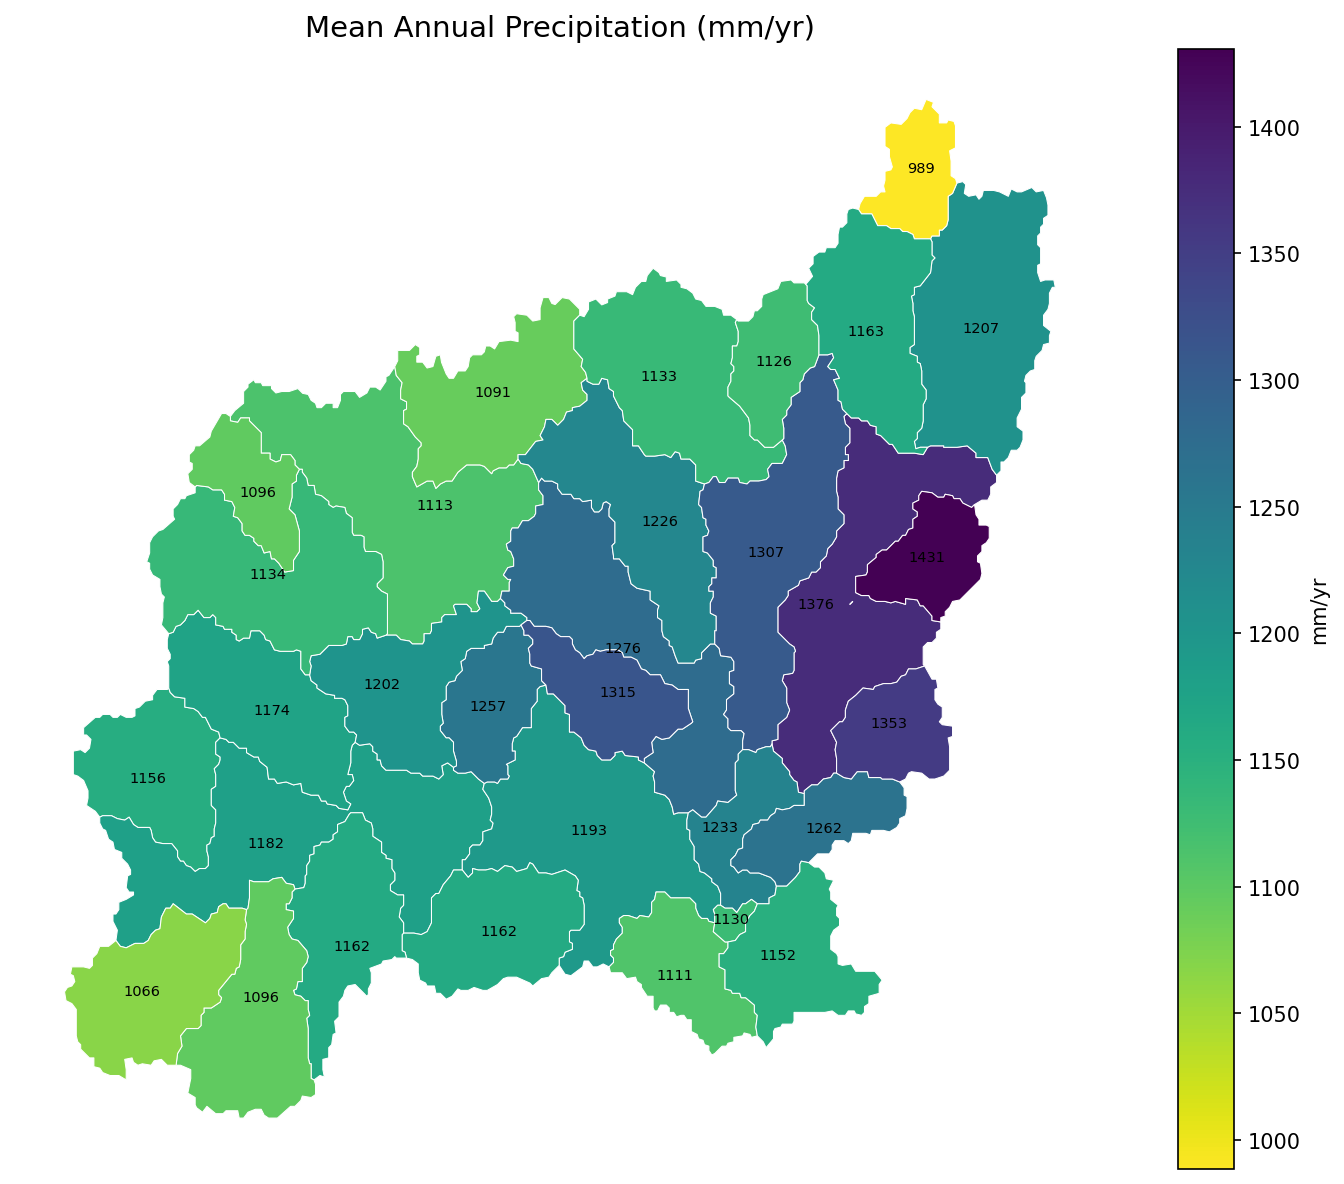

In [11]:
# Mean annual map of the selected variable
plot_mean_annual_basin_map(forcings_path, gpkg_path, var_name)

<div style="background-color:rgba(184,34,61,0.12); border-left:4px solid #E04A63; padding:6px 10px; border-radius:6px; font-size:14px; margin-top:4px; margin-bottom:8px;">
<strong>Spatially Averaged Forcing Map (Raw Gridded)</strong><br>
Spatial average calculated from the raw gridded forcing dataset together with the HydroFabric catchment geometries.<br>
<code>/home/jovyan/ngiab_preprocess_output/gage-02465493/forcings/raw_gridded_data.nc</code>
</div>


Saved PNG map to: /home/jovyan/workshop/figures/mean_annual_raw_gridded_precip_rate.png


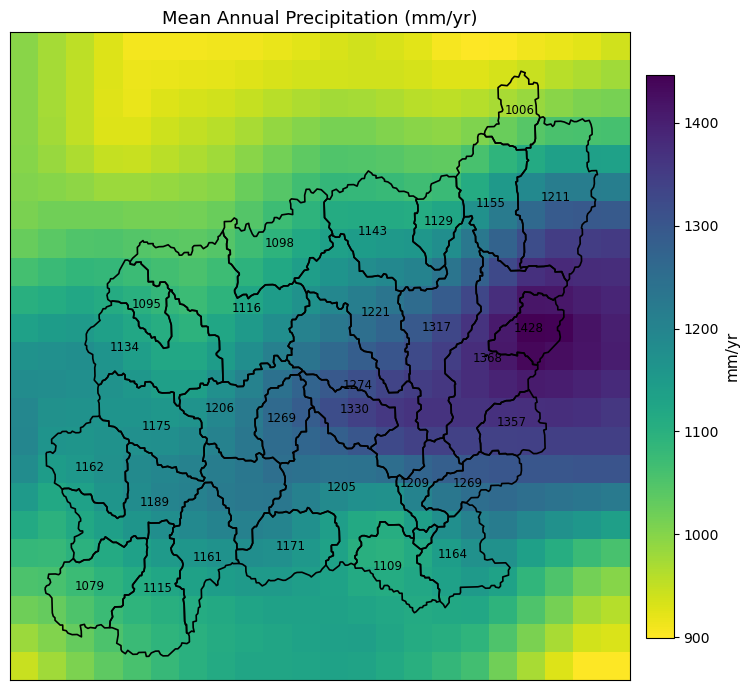

In [12]:
# Mean annual map from the raw gridded forcing
plot_raw_gridded_map(hydrofabric_id, var_name)

<div style="background:#9E1B32; border-left:6px solid #F0627A; padding:12px 16px; border-radius:8px; margin-top:0; margin-bottom:0;">
  <h3 style="margin:0; font-size:20px; font-weight:700; color:#fff5f7;">
    5. Create Model Configuration/Realization
  </h3>
</div>

<p style="margin-top:0; margin-bottom:0; padding-top:4px;">
Creates all the configuration files needed to run NextGen: <strong>realization.json</strong> for the model setup, <strong>troute.yaml</strong> for routing, and the model configurations of each divide (subcatchment) in the spatial domain of interest.
</p>

<div style="background-color:rgba(184,34,61,0.12); border-left: 5px solid #E04A63; padding: 12px; border-radius: 6px; font-family: 'Fira Code', monospace; font-size: 14px; margin-top: 12px;">
  <strong>Command:
  <pre style="margin-top: 10px; background-color:#1e1e1e; color:#ffffff; padding:10px; border-radius:6px; overflow-x:auto;"><code>!source /ngen/.venv/bin/activate && python -m ngiab_data_cli -i "$hydrofabric_id" -r --start "$start_date" --end "$end_date"</code></pre>
</div>

<table style="border-collapse: collapse; width: 100%; font-size: 14px;"> <thead> <tr style="background-color: #ffffff; color: #9E1B32;"> <th style="padding: 8px; text-align: left; color: #9E1B32; border-bottom: 2px solid #9E1B32;">Argument</th> <th style="padding: 8px; text-align: left; color: #9E1B32; border-bottom: 2px solid #9E1B32;">Description</th> </tr> </thead> <tbody> <tr> <td style="padding: 8px; text-align: left;"><code>!source /ngen/.venv/bin/activate</code></td> <td style="padding: 8px; text-align: left;">Turns on the Python virtual environment used by the <code>NextGen</code> modeling framework, so the right dependencies (e.g., <code>xarray</code>, <code>ngiab_data_cli</code> and <code>hydrofabric</code> libraries) are available when it runs.</td> </tr> <tr> <td style="padding: 8px; text-align: left;"><code>python -m ngiab_data_cli</code></td> <td style="padding: 8px; text-align: left;">Runs the <code>ngiab_data_cli</code> module as a script. This command-line interface (CLI) preprocesses data for NextGen HydroFabric subsets, including downloading, formatting and generating meteorological forcing files.</td> </tr> <tr> <td style="padding: 8px; text-align: left;"><code>-i "$hydrofabric_id"</code></td> <td style="padding: 8px; text-align: left;">Gives the unique HydroFabric subset ID (e.g., a gage or catchment identifier), which tells the script which region or watershed subset to prepare forcing data for.</td> </tr> <tr> <td style="padding: 8px; text-align: left;"><code>-r</code></td> <td style="padding: 8px; text-align: left;">Builds a realization for the given feature.</td> </tr> <tr> <td style="padding: 8px; text-align: left;"><code>--start "$start_date"</code></td> <td style="padding: 8px; text-align: left;">Sets the first date of the forcing dataset (e.g., <code>--start "2020-01-01"</code>); the CLI starts processing data from this date.</td> </tr> <tr> <td style="padding: 8px; text-align: left;"><code>--end "$end_date"</code></td> <td style="padding: 8px; text-align: left;">Sets the last date of the forcing dataset (e.g., <code>--end "2020-12-31"</code>); the CLI processes all data up to this date.</td> </tr> </tbody> </table> <div style="background-color:rgba(184,34,61,0.12); border-left: 5px solid #E04A63; padding: 12px; border-radius: 6px; font-family: 'Segoe UI', sans-serif; font-size: 14px; margin-top: 12px;"> 💡 <strong>Tip:</strong><br> 1) Further details and the official documentation are available at: <a href="https://pypi.org/project/ngiab-data-preprocess/" target="_blank">https://pypi.org/project/ngiab-data-preprocess/</a><br><br> 2) The files created by the <code>-r</code> (realization) command are saved under:<br> <code>/home/jovyan/ngiab_preprocess_output/{hydrofabric_id}/config</code><br> In this case, for example, the full path is:<br> <code>/home/jovyan/ngiab_preprocess_output/gage-02465493/config</code> </div>

In [13]:
# Set-up Model Configurations / Realization
# Use the variables defined earlier (`hydrofabric_id`, `start_date`, `end_date`) to
# generate the model configuration and realization files needed to run the model
if online == 'yes':
    !source /ngen/.venv/bin/activate && python -m ngiab_data_cli -i "$hydrofabric_id" -r --start "$start_date" --end "$end_date" --lstm_rust

⠴ loading<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)
⠹ loading
2026-11-06 23:08:15,398 - INFO - Getting catid for 02450250, in /home/jovyan/.ngiab/hydrofabric/v2.2/conus_nextgen.gpkg
2026-11-06 23:08:15,415 - INFO - Found cat-486182 from gage-02450250
2026-11-06 23:08:15,417 - INFO - Processing cat-486182 in /home/jovyan/workshop/ngiab_preprocess_output/gage-02450250
2026-11-06 23:08:18,884 - INFO - Upstream catchments: 31
2026-11-06 23:08:18,885 - INFO - Creating realization from 2017-10-01 00:00:00 to 2017-11-30 00:00:00...
2026-11-06 23:08:19,504 - INFO - Realization creation complete.
2026-11-06 23:08:19,504 - INFO - All operations completed successfully.
2026-11-06 23:08:19,504 - INFO - Output folder: file:////home/jovyan/workshop/ngiab_preprocess_output/gage-02450250


---

### ➡️ Next notebook: [02. NextGen Run](02.NextGen_Run.ipynb)